# 03. Deep Dive — Temporal


In [42]:
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from propensity.overview import build_dunnhumby_overview
from propensity.overview.activity_dashboard import (
    load_transaction_activity_dashboard,
    plot_transaction_activity_dashboard,
)
from propensity.schema.dunnhumby import DUNNHUMBY_CATALOG

In [43]:
raw_dir = Path("../data/raw/Dunnhumby")
report = build_dunnhumby_overview(raw_dir=raw_dir)

## 5. Time Coverage Summary

In [49]:
report.time_summary

,table,column,kind,unit,start_column,end_column,min,max,n_unique_non_missing,span,n_missing,missing_endpoint_rows,start_after_end_rows,invalid_clock_rows
0,transaction,DAY,ordinal,day_index,<NA>,<NA>,1,711,711,710,0,<NA>,<NA>,<NA>
1,transaction,WEEK_NO,ordinal,week,<NA>,<NA>,1,102,102,101,0,<NA>,<NA>,<NA>
2,transaction,TRANS_TIME,clock,HHMM,<NA>,<NA>,0,2359,1440,<NA>,0,<NA>,<NA>,0
3,campaign_desc,START_DAY,ordinal,day,<NA>,<NA>,224,659,27,435,0,<NA>,<NA>,<NA>
4,campaign_desc,END_DAY,ordinal,day,<NA>,<NA>,264,719,28,455,0,<NA>,<NA>,<NA>
5,campaign_desc,<NA>,interval,day,START_DAY,END_DAY,224,719,<NA>,495,0,0,0,<NA>
6,coupon_redempt,DAY,ordinal,day_index,<NA>,<NA>,225,704,328,479,0,<NA>,<NA>,<NA>
7,causal,WEEK_NO,ordinal,week,<NA>,<NA>,9,101,93,92,0,<NA>,<NA>,<NA>


## 10. Transaction Activity Dashboard

- Giao dịch được đếm theo `BASKET_ID` unique.
- Vì dataset chỉ có chỉ số `DAY`, mỗi chu kỳ 365 ngày được chia tương đối thành 12 tháng để so sánh Năm 1 và Năm 2.
- Khung giờ: Sáng 05–10h, Trưa 11–13h, Chiều 14–17h, Tối 18–04h.
- Độ dài lịch sử household = `max(DAY) - min(DAY) + 1`.

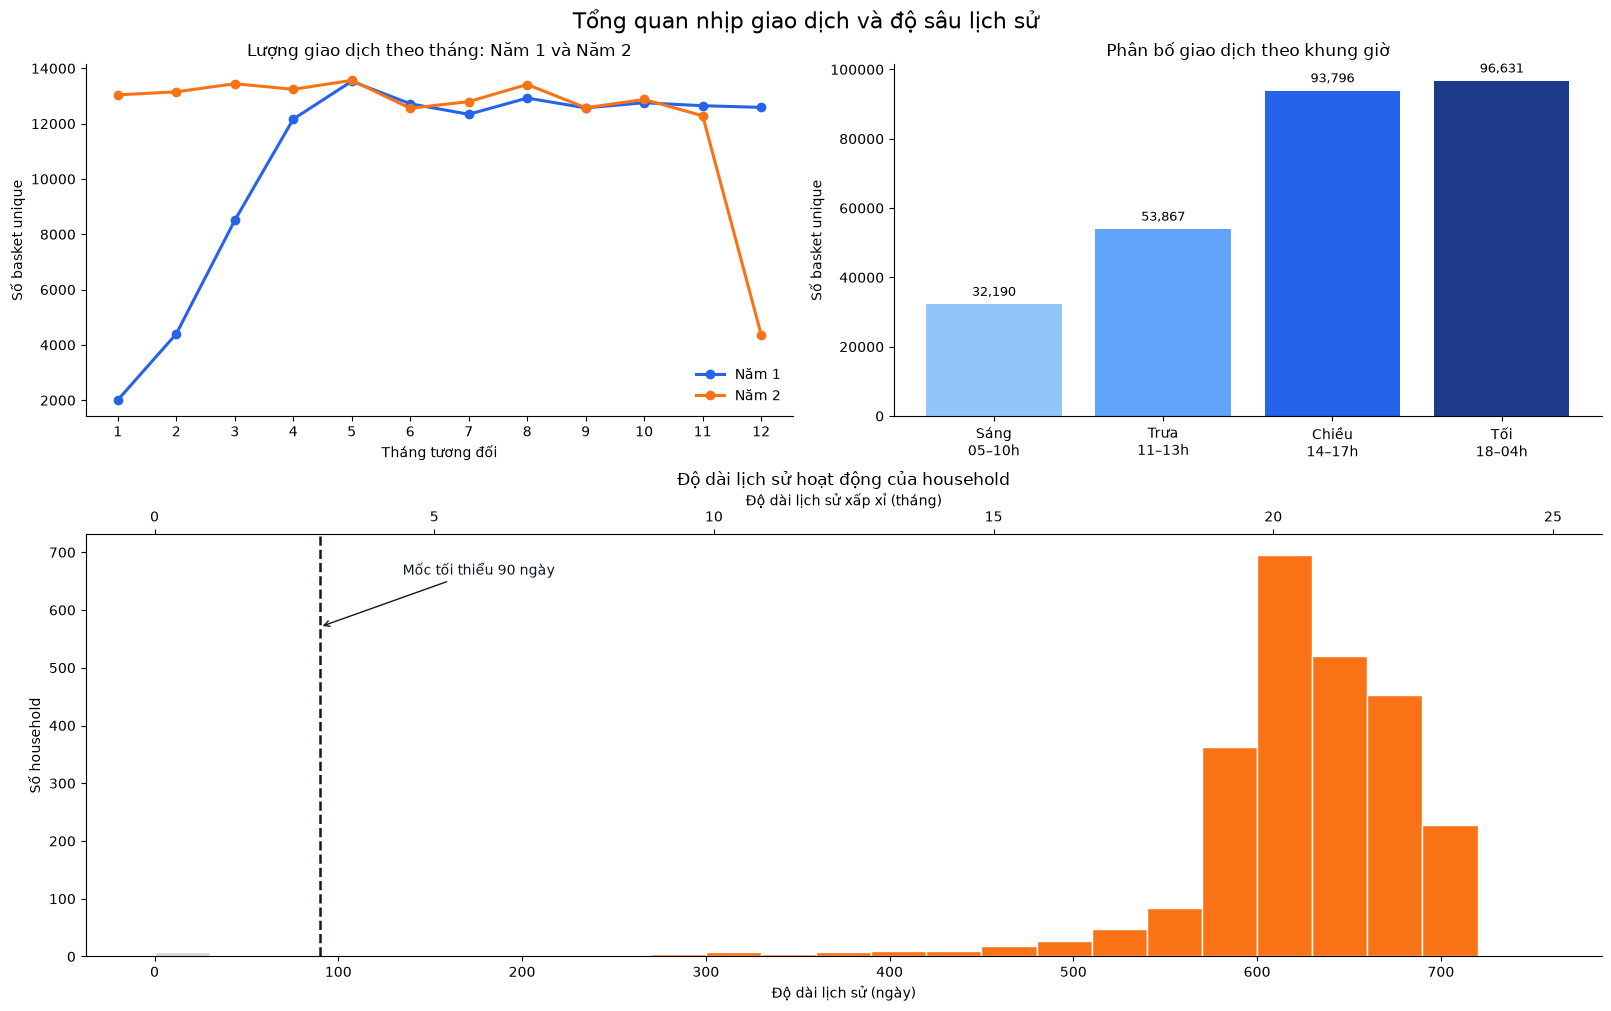

In [69]:
activity_dashboard = load_transaction_activity_dashboard(
    raw_dir / "transaction_data.csv"
)
activity_figure = plot_transaction_activity_dashboard(activity_dashboard)
plt.show()

## 11. Household activity coverage theo tuần

Mỗi ô household × week chứa số `BASKET_ID` distinct. Biểu đồ B dùng toàn bộ household và là biểu đồ ưu tiên để kết luận định lượng. Trong phần thống kê, household "chỉ mua trong vài tuần" được định nghĩa là active không quá 4 tuần.

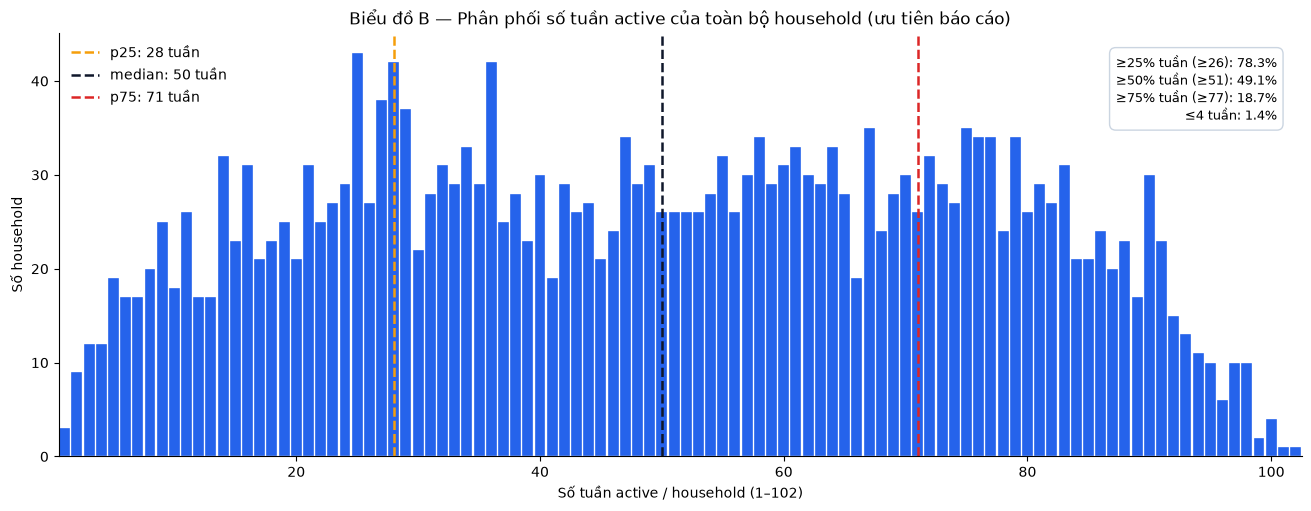

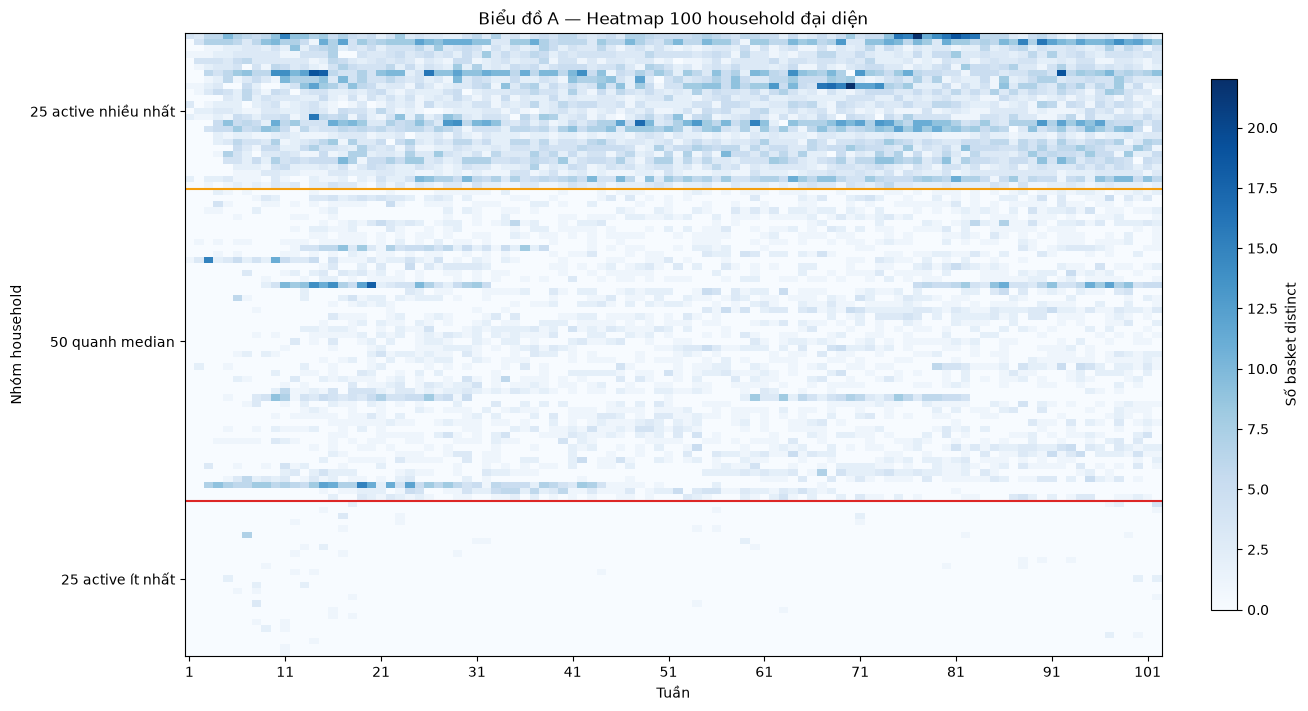

,value
n_households,2500.00
n_observed_weeks,102.00
p25_active_weeks,28.00
median_active_weeks,50.00
p75_active_weeks,71.00
pct_active_at_least_25pct_weeks,78.28
pct_active_at_least_50pct_weeks,49.08
pct_active_at_least_75pct_weeks,18.68
pct_active_at_most_4_weeks,1.44


In [70]:
transaction_baskets = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=["household_key", "BASKET_ID", "DAY", "WEEK_NO"],
)

coverage_household_week = (
    transaction_baskets
    .dropna(subset=["household_key", "BASKET_ID", "WEEK_NO"])
    .groupby(["household_key", "WEEK_NO"])["BASKET_ID"]
    .nunique()
    .unstack(fill_value=0)
    .sort_index(axis=1)
)
coverage_household_week.columns = [
    f"WEEK_{int(week):03d}" for week in coverage_household_week.columns
]
coverage_household_week.insert(
    0, "active_weeks", coverage_household_week.gt(0).sum(axis=1)
)
coverage_household_week = coverage_household_week.sort_values(
    ["active_weeks", "household_key"], ascending=[False, True]
)
week_columns = [
    column for column in coverage_household_week.columns if column.startswith("WEEK_")
]
n_observed_weeks = len(week_columns)
household_active_weeks = coverage_household_week["active_weeks"]

# Biểu đồ B — toàn bộ household; ưu tiên cho báo cáo.
active_week_quantiles = household_active_weeks.quantile([0.25, 0.50, 0.75])
active_week_quantiles.index = ["p25", "median", "p75"]
activity_thresholds = {
    "25% số tuần quan sát": ceil(n_observed_weeks * 0.25),
    "50% số tuần quan sát": ceil(n_observed_weeks * 0.50),
    "75% số tuần quan sát": ceil(n_observed_weeks * 0.75),
}
active_week_metrics = pd.Series({
    "n_households": int(len(household_active_weeks)),
    "n_observed_weeks": n_observed_weeks,
    "p25_active_weeks": float(active_week_quantiles.loc["p25"]),
    "median_active_weeks": float(active_week_quantiles.loc["median"]),
    "p75_active_weeks": float(active_week_quantiles.loc["p75"]),
    "pct_active_at_least_25pct_weeks": float(
        (household_active_weeks >= activity_thresholds["25% số tuần quan sát"]).mean() * 100
    ),
    "pct_active_at_least_50pct_weeks": float(
        (household_active_weeks >= activity_thresholds["50% số tuần quan sát"]).mean() * 100
    ),
    "pct_active_at_least_75pct_weeks": float(
        (household_active_weeks >= activity_thresholds["75% số tuần quan sát"]).mean() * 100
    ),
    "pct_active_at_most_4_weeks": float(
        (household_active_weeks <= 4).mean() * 100
    ),
}, name="value").to_frame()

active_week_counts = (
    household_active_weeks
    .value_counts()
    .reindex(range(1, n_observed_weeks + 1), fill_value=0)
    .sort_index()
)
activity_distribution_figure, activity_distribution_axis = plt.subplots(
    figsize=(13, 5), layout="constrained"
)
activity_distribution_axis.bar(
    active_week_counts.index,
    active_week_counts.values,
    width=0.9,
    color="#2563EB",
    edgecolor="white",
    linewidth=0.25,
)
for label, color in (("p25", "#F59E0B"), ("median", "#0F172A"), ("p75", "#DC2626")):
    value = float(active_week_quantiles.loc[label])
    activity_distribution_axis.axvline(
        value, color=color, linestyle="--", linewidth=1.8,
        label=f"{label}: {value:g} tuần",
    )
metrics_text = "\n".join([
    f"≥25% tuần (≥{activity_thresholds['25% số tuần quan sát']}): "
    f"{active_week_metrics.loc['pct_active_at_least_25pct_weeks', 'value']:.1f}%",
    f"≥50% tuần (≥{activity_thresholds['50% số tuần quan sát']}): "
    f"{active_week_metrics.loc['pct_active_at_least_50pct_weeks', 'value']:.1f}%",
    f"≥75% tuần (≥{activity_thresholds['75% số tuần quan sát']}): "
    f"{active_week_metrics.loc['pct_active_at_least_75pct_weeks', 'value']:.1f}%",
    f"≤4 tuần: {active_week_metrics.loc['pct_active_at_most_4_weeks', 'value']:.1f}%",
])
activity_distribution_axis.text(
    0.98, 0.95, metrics_text, transform=activity_distribution_axis.transAxes,
    ha="right", va="top", fontsize=9,
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#CBD5E1"},
)
activity_distribution_axis.set(
    title="Biểu đồ B — Phân phối số tuần active của toàn bộ household (ưu tiên báo cáo)",
    xlabel=f"Số tuần active / household (1–{n_observed_weeks})",
    ylabel="Số household",
    xlim=(0.5, n_observed_weeks + 0.5),
)
activity_distribution_axis.spines[["top", "right"]].set_visible(False)
activity_distribution_axis.legend(frameon=False)
plt.show()

# Biểu đồ A — 100 household đại diện.
household_activity_rank = (
    coverage_household_week[["active_weeks"]]
    .reset_index()
    .sort_values(["active_weeks", "household_key"], ascending=[False, True])
)
most_active = household_activity_rank.head(25)
least_active = household_activity_rank.tail(25).sort_values(
    ["active_weeks", "household_key"], ascending=[False, True]
)
excluded_households = set(most_active["household_key"]) | set(least_active["household_key"])
median_active_weeks = float(active_week_quantiles.loc["median"])
median_active = (
    household_activity_rank
    .loc[lambda frame: ~frame["household_key"].isin(excluded_households)]
    .assign(distance_to_median=lambda frame: (
        frame["active_weeks"] - median_active_weeks
    ).abs())
    .sort_values(["distance_to_median", "active_weeks", "household_key"])
    .head(50)
    .sort_values(["active_weeks", "household_key"], ascending=[False, True])
)
representative_households = pd.concat(
    [most_active, median_active.drop(columns="distance_to_median"), least_active],
    ignore_index=True,
)
representative_coverage = coverage_household_week.loc[
    representative_households["household_key"], week_columns
]

representative_heatmap_figure, representative_heatmap_axis = plt.subplots(
    figsize=(13, 7), layout="constrained"
)
representative_heatmap_image = representative_heatmap_axis.imshow(
    representative_coverage.to_numpy(dtype="float64"),
    aspect="auto",
    interpolation="nearest",
    cmap="Blues",
)
representative_heatmap_axis.axhline(24.5, color="#F59E0B", linewidth=1.5)
representative_heatmap_axis.axhline(74.5, color="#DC2626", linewidth=1.5)
week_tick_positions = list(range(0, n_observed_weeks, 10))
representative_heatmap_axis.set_xticks(
    week_tick_positions,
    [int(week_columns[position].split("_")[1]) for position in week_tick_positions],
)
representative_heatmap_axis.set_yticks(
    [12, 49, 87],
    ["25 active nhiều nhất", "50 quanh median", "25 active ít nhất"],
)
representative_heatmap_axis.set(
    title="Biểu đồ A — Heatmap 100 household đại diện",
    xlabel="Tuần",
    ylabel="Nhóm household",
)
representative_heatmap_figure.colorbar(
    representative_heatmap_image,
    ax=representative_heatmap_axis,
    label="Số basket distinct",
    shrink=0.85,
)
plt.show()

active_week_metrics